# J2 : UK-DALE, traitements A et B

**Objectif.** Montrer comment un fichier FLAC (deux canaux, 16 kHz) devient des indicateurs électriques par fenêtres d'une seconde
(traitement A), puis des variables temporelles (traitement B).

Comme pour MetroPT-3 : le notebook **appelle** `src/ukdale_reference.py` et `src/datamining_features.py`, il ne les remplace pas, et il
passe sur des **données synthétiques** (annoncées dans les figures) si le vrai FLAC est absent.

In [1]:
from pathlib import Path
import json, sys, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Racine du projet (ce notebook est dans notebooks/) : on importe le code de src/, on ne le recopie pas.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
TMP = Path(tempfile.mkdtemp(prefix="bigdata_nb_"))   # fichiers temporaires : data/ n'est jamais modifié

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (9, 3.6)})
print("Racine du projet :", ROOT)

import soundfile as sf
from src.common import compare_results
from src.ukdale_reference import accumulate_blocks, compute_features, finalize, iter_flac_blocks, read_calibration
from src.datamining_features import ukdale_datamining

Racine du projet : /home/claude/BigData_Project


## 1. Les formules (guide §8)

Pour chaque fenêtre de $n = 16\,000$ échantillons (1 seconde), avec $U$ en volts et $I$ en ampères **après calibration** :

$$I_{\mathrm{RMS}}=\sqrt{\frac{\sum I_i^2}{n}},\qquad U_{\mathrm{RMS}}=\sqrt{\frac{\sum U_i^2}{n}},\qquad P_{\mathrm{moy}}=\frac{\sum U_i I_i}{n}\ \text{(W)}$$

La calibration vient de `calibration_house_1.cfg` : $U = \text{canal 0} \times \texttt{volts\_per\_adc\_step}$ et $I = \text{canal 1} \times \texttt{amps\_per\_adc\_step}$.
Une amplitude brute n'est ni un volt ni un ampère : sans calibration, les résultats n'ont aucun sens.

**Calcul par blocs.** Le fichier n'est jamais chargé en entier. Chaque bloc fournit, par fenêtre, les sommes $n$, $\sum I^2$, $\sum U^2$, $\sum UI$ ;
une fenêtre coupée entre deux blocs est reconstituée en additionnant ces sommes. La **dernière fenêtre est conservée même incomplète**, avec son effectif réel.

## 2. Exemple pédagogique du guide (§8)

Deux mesures synchrones : $U=[220,220]$ V et $I=[2,4]$ A. *(Chiffres du guide, pas un enregistrement UK-DALE.)*
Attendu : $I_{\mathrm{RMS}}=\sqrt{(4+16)/2}=\sqrt{10}\approx 3{,}162$ A et $P=(220\times2+220\times4)/2=660$ W.

In [2]:
brut = np.array([[220, 2], [220, 4]], dtype=np.int32)                 # canal 0 = tension, canal 1 = courant
unite = {"volts_per_adc_step": 1.0, "amps_per_adc_step": 1.0}         # calibration neutre pour l'exemple
f = finalize(accumulate_blocks([brut], unite, 2), 2).iloc[0]
print(f"I_rms = {f.i_rms:.4f} A   (attendu {np.sqrt(10):.4f})")
print(f"U_rms = {f.u_rms:.1f} V")
print(f"P_moy = {f.p_mean:.1f} W   (attendu 660)")

I_rms = 3.1623 A   (attendu 3.1623)
U_rms = 220.0 V
P_moy = 660.0 W   (attendu 660)


## 3. Les données utilisées dans ce notebook

In [3]:
FLAC = next(iter(sorted((ROOT / "data" / "ukdale").glob("vi-*.flac"))), None)
CFG = ROOT / "data" / "ukdale" / "calibration_house_1.cfg"
SYNTHETIC = FLAC is None or not CFG.exists()
TAG = "  [DONNÉES SYNTHÉTIQUES]" if SYNTHETIC else ""

if SYNTHETIC:
    # Calibration de la maison 1 relevée dans l'audit J1 ; signal SYNTHÉTIQUE de 120 s :
    # tension secteur 230 V, courant 2 A puis 8 A à partir de 60 s (cos phi = 0,8), dernière fenêtre incomplète (9 173 échantillons).
    CAL = {"volts_per_adc_step": 1.90101491444e-07, "amps_per_adc_step": 4.9224284384e-08, "phase_difference": -2.92555759986}
    n = 120 * 16_000 + 9_173
    t = np.arange(n) / 16_000
    u = 230 * np.sqrt(2) * np.sin(2 * np.pi * 50 * t)
    i_rms_cible = np.where(t < 60, 2.0, 8.0)
    i = i_rms_cible * np.sqrt(2) * np.sin(2 * np.pi * 50 * t - np.arccos(0.8))
    brut = np.stack([np.round(u / CAL["volts_per_adc_step"]), np.round(i / CAL["amps_per_adc_step"])], axis=1).astype(np.int64)
    brut = (brut.astype(np.int32)) & ~np.int32(0xFF)                   # PCM 24 bits : comme lu par libsndfile en int32
    FLAC = TMP / "vi-1363392000_synthetique.flac"
    sf.write(str(FLAC), brut, 16_000, subtype="PCM_24", format="FLAC")
    print("ATTENTION : fichier FLAC et calibration réels introuvables. Exemple sur signal synthétique.")
else:
    CAL = read_calibration(CFG)
print("Fichier :", FLAC.name)
print("Calibration :", {k: CAL[k] for k in ("volts_per_adc_step", "amps_per_adc_step")})
info = sf.info(str(FLAC))
print(f"Format : {info.format}/{info.subtype}, {info.channels} canaux, {info.samplerate} Hz, {info.frames} échantillons ({info.frames / info.samplerate:.2f} s)")

ATTENTION : fichier FLAC et calibration réels introuvables. Exemple sur signal synthétique.
Fichier : vi-1363392000_synthetique.flac
Calibration : {'volts_per_adc_step': 1.90101491444e-07, 'amps_per_adc_step': 4.9224284384e-08}
Format : FLAC/PCM_24, 2 canaux, 16000 Hz, 1929173 échantillons (120.57 s)


## 4. La calibration : du nombre brut au volt et à l'ampère

Le FLAC est lu en `int32` (pour du PCM 24 bits, libsndfile renvoie la valeur sur 32 bits, soit la valeur 24 bits multipliée par 256).
Les coefficients de la maison 1 sont cohérents avec cette échelle : la pleine échelle correspond à environ 408 V crête.

3 premiers échantillons bruts (canal 0, canal 1) : [[0, -34476032], [33593600, -33566976], [67174656, -32644864]]
Après calibration (V, A)                        : [[0.0, -1.697], [6.386, -1.652], [12.77, -1.607]]
Pleine échelle en tension : 408 V crête ; amplitude relevée : 325 V crête


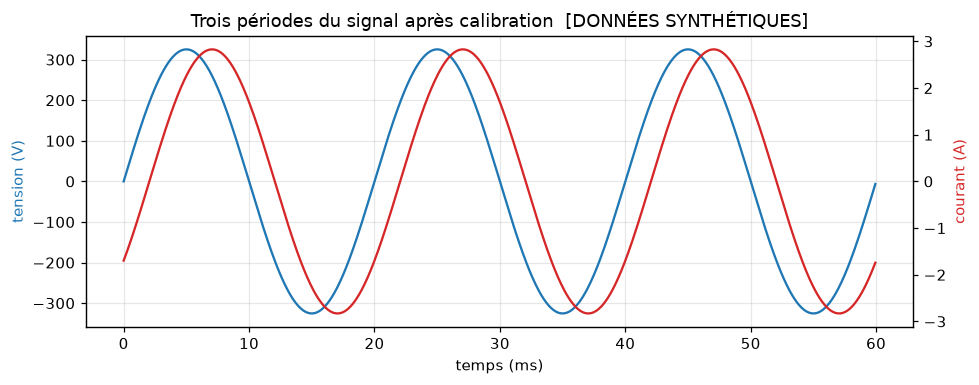

In [4]:
premier = next(iter_flac_blocks(FLAC, 960))                            # 960 échantillons = 60 ms = 3 périodes à 50 Hz
u = premier[:, 0].astype(float) * CAL["volts_per_adc_step"]
i = premier[:, 1].astype(float) * CAL["amps_per_adc_step"]
t_ms = np.arange(len(premier)) / 16_000 * 1000

print("3 premiers échantillons bruts (canal 0, canal 1) :", premier[:3].tolist())
print("Après calibration (V, A)                        :", np.round(np.column_stack([u[:3], i[:3]]), 3).tolist())
print(f"Pleine échelle en tension : {2**31 * CAL['volts_per_adc_step']:.0f} V crête ; amplitude relevée : {np.abs(u).max():.0f} V crête")

fig, ax = plt.subplots()
ax.plot(t_ms, u, color="#1f77b4", label="tension (canal 0)")
ax.set_xlabel("temps (ms)"); ax.set_ylabel("tension (V)", color="#1f77b4")
ax2 = ax.twinx(); ax2.plot(t_ms, i, color="#d62728", label="courant (canal 1)"); ax2.set_ylabel("courant (A)", color="#d62728"); ax2.grid(False)
ax.set_title("Trois périodes du signal après calibration" + TAG)
plt.tight_layout(); plt.show()

## 5. Traitement A : indicateurs par fenêtres d'une seconde

In [5]:
MAX_SECONDS = None        # mettre par exemple 600 pour ne traiter que les 10 premières minutes (extrait)
report = {}
feats = compute_features(FLAC, CAL, max_seconds=MAX_SECONDS, report=report)
display(feats.head(4))
print("Dernières fenêtres (la dernière est incomplète mais conservée, avec son effectif réel) :")
display(feats.tail(3))

,window_index,window_start_s,window_start_utc,n_samples,is_complete,i_rms,u_rms,p_mean
0,0,0.0,2013-03-16 00:00:00,16000,True,2.0,229.999999,368.000009
1,1,1.0,2013-03-16 00:00:01,16000,True,2.0,229.999999,368.000009
2,2,2.0,2013-03-16 00:00:02,16000,True,2.0,229.999999,368.000009
3,3,3.0,2013-03-16 00:00:03,16000,True,2.0,229.999999,368.000009


Dernières fenêtres (la dernière est incomplète mais conservée, avec son effectif réel) :


,window_index,window_start_s,window_start_utc,n_samples,is_complete,i_rms,u_rms,p_mean
118,118,118.0,2013-03-16 00:01:58,16000,True,8.000000,229.999999,1471.999946
119,119,119.0,2013-03-16 00:01:59,16000,True,8.000000,229.999999,1471.999946
120,120,120.0,2013-03-16 00:02:00,9173,False,7.981491,229.711981,1463.806422


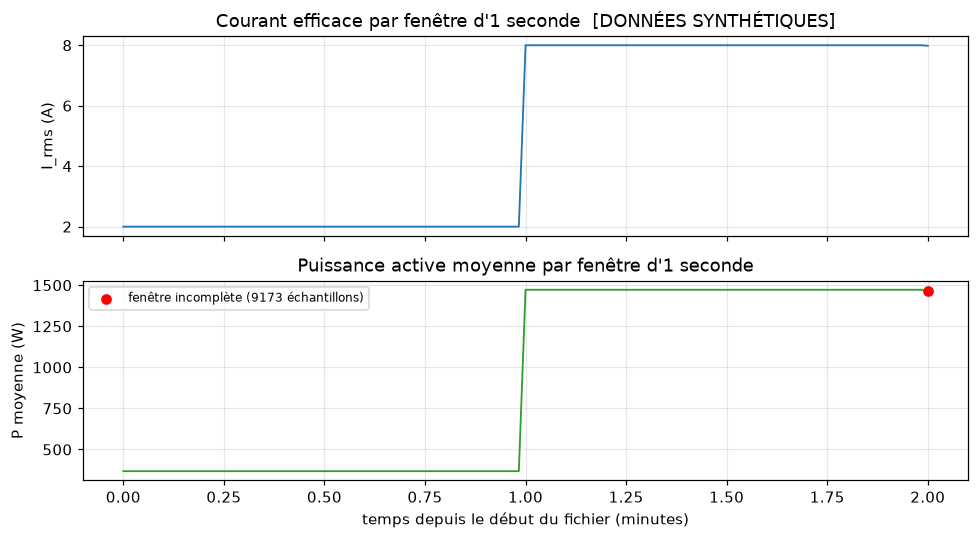

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
x = feats.window_start_s / 60
ax1.plot(x, feats.i_rms, lw=1.2); ax1.set_ylabel("I_rms (A)"); ax1.set_title("Courant efficace par fenêtre d'1 seconde" + TAG)
ax2.plot(x, feats.p_mean, lw=1.2, color="#2ca02c"); ax2.set_ylabel("P moyenne (W)"); ax2.set_title("Puissance active moyenne par fenêtre d'1 seconde")
inc = feats[~feats.is_complete]
ax2.scatter(inc.window_start_s / 60, inc.p_mean, color="red", zorder=3, label=f"fenêtre incomplète ({int(inc.n_samples.iloc[0])} échantillons)")
ax2.legend(fontsize=8); ax2.set_xlabel("temps depuis le début du fichier (minutes)")
plt.tight_layout(); plt.show()

## 6. Le résultat ne dépend pas de la taille des blocs

Les 30 premières secondes sont lues avec des blocs de 777 échantillons (qui coupent presque toutes les fenêtres) puis avec les blocs par défaut ;
la tolérance est $|v-r|\le 10^{-9}+10^{-9}|r|$.

In [7]:
a = compute_features(FLAC, CAL, blocksize=777, max_seconds=30)
b = compute_features(FLAC, CAL, blocksize=160_000, max_seconds=30)
compare_results(a, b, ["window_index"])
print(f"OK : {len(a)} fenêtres identiques entre blocs de 777 échantillons et blocs de 160 000.")

OK : 30 fenêtres identiques entre blocs de 777 échantillons et blocs de 160 000.


## 7. Contrôles de qualité

Pour le vrai fichier, la colonne « attendu » reprend la fiche d'audit J1. La tension de 243 V mérite une discussion dans le rapport (J1, section 3.3) : le contrôle ne prouve pas l'association des canaux, il la rend plausible.

In [8]:
obs = {
    "total_samples": report["total_samples"], "windows": report["windows"],
    "incomplete_windows": report["incomplete_windows"], "last_window_samples": report["last_window_samples"],
    "global_u_rms_v": round(report["global_u_rms_v"], 2), "global_i_rms_a": round(report["global_i_rms_a"], 3),
    "mapping_plausible": report["mapping_plausible"],
}
tab = pd.DataFrame({"observé": obs})
if SYNTHETIC or MAX_SECONDS is not None:
    tab["attendu (J1)"] = "n/a"
else:
    j1 = {"total_samples": 57_593_173, "windows": 3600, "incomplete_windows": 1, "last_window_samples": 9173, "mapping_plausible": True}
    tab["attendu (J1)"] = pd.Series({**j1, "global_u_rms_v": "≈ 243,3", "global_i_rms_a": "≈ 1,06"})
display(tab)
print("phase_difference (calibration) : consignée dans le rapport, non appliquée :", report["calibration"].get("phase_difference"))

,observé,attendu (J1)
total_samples,1929173,n/a
windows,121,n/a
incomplete_windows,1,n/a
last_window_samples,9173,n/a
global_u_rms_v,230.0,n/a
global_i_rms_a,5.843,n/a
mapping_plausible,True,n/a


phase_difference (calibration) : consignée dans le rapport, non appliquée : -2.92555759986


## 8. Traitement B : variables temporelles

Même principe que pour MetroPT-3 : variation par rapport à la fenêtre précédente, moyenne historique pondérée sur la durée précédente (strictement antérieure),
fenêtres manquantes laissées identifiables. Avec des fenêtres d'**une seconde**, les 5 minutes de référence font **300 fenêtres** : sur un fichier d'une heure,
les 300 premières lignes ont un historique incomplet (`hist_complete = False`), ce qui est signalé et non masqué.

In [9]:
HIST_MIN = 5 if len(feats) > 600 else 10 / 60        # 5 min ; sur l'exemple synthétique de 2 min on prend 10 s
dm = ukdale_datamining(feats, history_minutes=HIST_MIN)
cols = ["window_index", "is_missing_window", "n_samples", "p_mean", "p_mean_variation", "p_mean_hist_mean", "p_mean_vs_hist", "hist_n_windows", "hist_complete"]
print(f"Historique : {HIST_MIN * 60:.0f} s = {int(round(HIST_MIN * 60))} fenêtres")
display(dm[cols].head(3))
k = int(dm.p_mean_variation.abs().idxmax())
print("Fenêtre où la puissance varie le plus par rapport à la précédente :")
display(dm[cols].iloc[max(k - 2, 0): k + 3])

Historique : 10 s = 10 fenêtres


,window_index,is_missing_window,n_samples,p_mean,p_mean_variation,p_mean_hist_mean,p_mean_vs_hist,hist_n_windows,hist_complete
0,0,False,16000,368.000009,NaN,NaN,NaN,0,False
1,1,False,16000,368.000009,0.0,368.000009,0.0,1,False
2,2,False,16000,368.000009,0.0,368.000009,0.0,2,False


Fenêtre où la puissance varie le plus par rapport à la précédente :


,window_index,is_missing_window,n_samples,p_mean,p_mean_variation,p_mean_hist_mean,p_mean_vs_hist,hist_n_windows,hist_complete
58,58,False,16000,368.000009,0.000000,368.000009,0.000000,10,True
59,59,False,16000,368.000009,0.000000,368.000009,0.000000,10,True
60,60,False,16000,1471.999946,1103.999937,368.000009,1103.999937,10,True
61,61,False,16000,1471.999946,0.000000,478.400002,993.599943,10,True
62,62,False,16000,1471.999946,0.000000,588.799996,883.199950,10,True


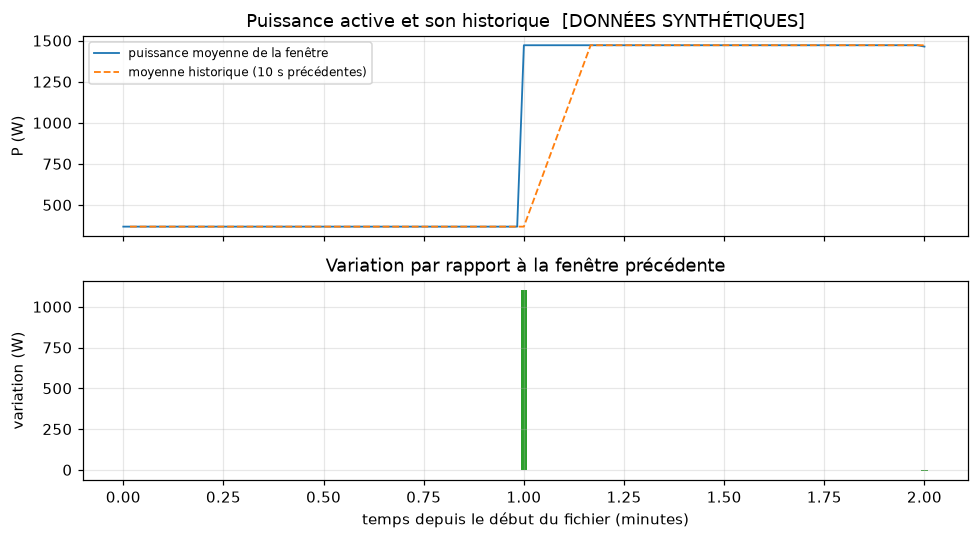

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
x = dm.window_index / 60
ax1.plot(x, dm.p_mean, lw=1.2, label="puissance moyenne de la fenêtre")
ax1.plot(x, dm.p_mean_hist_mean, lw=1.2, ls="--", label=f"moyenne historique ({HIST_MIN * 60:.0f} s précédentes)")
ax1.set_ylabel("P (W)"); ax1.set_title("Puissance active et son historique" + TAG); ax1.legend(fontsize=8)
ax2.bar(x, dm.p_mean_variation, width=1 / 60, color="#2ca02c")
ax2.set_ylabel("variation (W)"); ax2.set_xlabel("temps depuis le début du fichier (minutes)"); ax2.set_title("Variation par rapport à la fenêtre précédente")
plt.tight_layout(); plt.show()

## 9. À retenir et limites

- Ce notebook **ne remplace pas** `src/ukdale_reference.py` ni `src/datamining_features.py` : il les appelle et les explique.
- La calibration est appliquée avant tout calcul ; `phase_difference` n'est pas appliquée (le guide ne prévoit que la mise à l'échelle en volts et en ampères).
- Un seul fichier FLAC à la fois : les fenêtres à cheval sur deux fichiers successifs ne sont pas gérées (à traiter pour les lots de plusieurs fichiers).
- À confirmer : que le FLAC vient bien de `house_1` (sinon la calibration ne s'applique pas), et le sens du suffixe du nom du fichier.
- Les chiffres des sections 2 et 4 (exemple √10, 660 W) illustrent les formules ; les résultats mesurés sont ceux des sections 5 à 8 lorsque le fichier réel est présent.